<a href="https://colab.research.google.com/github/zerogradlabs/zerograd-python/blob/main/examples/use-cases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ZeroGrad in six use cases

One notebook that walks the whole SDK on public data, from `pip install` to production feedback:

1. **Churn**: a classification championship on the IBM Telco customers.
2. **House prices**: a regression championship on California housing.
3. **Before you ship**: cross-validation, the threshold a missed churner justifies, and the columns that matter.
4. **Odd rows**: anomaly detection on the same customers, with a few broken records planted.
5. **Segments**: clustering wines with no labels.
6. **Production feedback** (optional, needs an API key): predictions on the platform, outcomes sent back, performance by cohort.

Everything up to step 5 runs locally, with no account. A GPU runtime makes it faster (*Runtime → Change runtime type → T4 GPU*), but CPU works; the samples are kept small so the whole notebook finishes in a few minutes either way. The first championship downloads each model's weights from its official repository, once.

Each step links to a longer notebook if you want to go deeper.

In [1]:
!pip install -q zerograd

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import zerograd
from zerograd import ZeroGrad

print("zerograd", zerograd.__version__)
zg = ZeroGrad(remote=False)   # local, even if ZEROGRAD_API_KEY is set; step 6 uses the platform
zerograd.list_models()

/home/runner/work/zerograd-python/zerograd-python/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
◆ ZeroGrad 0.2.4 · local · 2 models ready: TabPFN v2, TabICLv2


  Zero gradients were harmed.


zerograd 0.2.4


Model,Use,Tasks,Installed,remote=True,License · weights,Notes
TabICLv2tabicl-v2,Commercial use,classification regression anomaly_detection imputation synthetic_data,✓,✓,BSD-3-ClauseWeights: huggingface.co/jingang/TabICL,
TabPFN v2tabpfn-v2,Commercial use,classification regression anomaly_detection imputation synthetic_data,✓,✓,Prior Labs License v1.0 (Apache 2.0 with attribution)Weights: huggingface.co/Prior-Labs/TabPFN-v2-clf,Show: “Built with PriorLabs-TabPFN”
Mitra-v2mitra-v2,Commercial use,classification regression,"—pip install ""zerograd[mitra]""",—,Apache 2.0Weights: huggingface.co/autogluon/mitra-classifier-2,Zero-shot (no fine-tuning). The published benchmark numbers use fine-tuning with bagging on a GPU.
TabDPTtabdpt,Commercial use,classification regression,"—pip install ""zerograd[tabdpt]""",—,Apache 2.0Weights: huggingface.co/Layer6/TabDPT,
FoMo-0Dfomo-0d,Commercial use,anomaly_detection,✓,—,MITWeights: huggingface.co/YuchenShen/FoMo-0D,"Zero-shot outlier detection (Shen, Wen, Akoglu; CMU, ICML 2025). Up to 100 features; more are subsampled."
Mitramitra,Commercial use,classification regression,"—pip install ""zerograd[mitra]""",—,Apache 2.0Weights: huggingface.co/autogluon/mitra-classifier,
ZEUSzeus,Commercial use,clustering,✓,—,Apache 2.0Weights: github.com/gmum/zeus (checkpoint on the authors' Google Drive),"Zero-shot embeddings for clustering (Marszałek et al., Jagiellonian University, 2025), clustered with k-means. Embeds up to 2,000 rows at once."
EXAONE Tabular (LG)exaone-tabular,Non-commercial,classification regression,"—pip install ""exaonetabular @ git+https://github.com/LGAI-Research/EXAONE-Tabular.git""",—,EXAONE AI Model License 1.2 - NC (code BSD-3)Weights: huggingface.co/LG-AI-Research/EXAONE-Tabular,Accept first: Read and accept the license on the model page before useExperimental adapter. Not for production or commercial use.
LimiX-2 (Stable AI)limix-2,Non-commercial,classification regression imputation,—git clone https://github.com/limix-ldm-ai/LimiX && pip install -e LimiX (needs Python 3.12+),—,StableAI LimiX Non-Commercial LicenseWeights: huggingface.co/stable-ai/LimiX-2,Accept first: Read and accept the license on the model page before useExperimental adapter. Not for production or commercial use.
TabFM 1.0 (Google)tabfm,Non-commercial,classification regression,"—pip install ""tabfm[pytorch]""",—,TabFM Non-Commercial License v1.0 (code Apache 2.0)Weights: huggingface.co/google/tabfm-1.0.0-pytorch,Accept first: Read and accept the license on the model page before useExperimental adapter. Not for production or commercial use.


`list_models()` is the catalog: which task each model runs, its license and whether you can use it commercially. Non-commercial models stay off unless you ask for them by name.

## 1. Churn: who is about to leave?

The Telco customer table IBM publishes: one row per customer, with contract, services, charges and whether they left last month. We take 2,000 customers to learn from and keep 1,000 aside as "next month's" customers.

In [3]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
telco = pd.read_csv(url)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")   # a few blanks for brand-new customers
telco = telco.sample(3_000, random_state=0)

history, upcoming = telco.iloc[:2_000], telco.iloc[2_000:]
print(telco.shape, "churn rate", round((telco["Churn"] == "Yes").mean(), 3))
telco.head()

(3000, 21) churn rate 0.269


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2200,6296-DDOOR,Female,0,No,No,19,Yes,No,DSL,No,...,No,No,Yes,No,One year,No,Electronic check,58.20,1045.25,No
4627,3680-CTHUH,Male,0,No,No,60,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Credit card (automatic),116.60,7049.50,No
3225,4931-TRZWN,Female,0,No,No,13,Yes,No,DSL,Yes,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,71.95,923.85,No
2828,8559-WNQZS,Male,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.45,20.45,No
3768,3537-HPKQT,Female,0,Yes,No,55,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Credit card (automatic),77.75,4266.40,No


`create` runs the championship: every installed model reads the same context, all of them are scored on the same holdout, and the best by ROC AUC becomes the champion. `customerID` is an identifier, so it goes in `drop`.

In [4]:
churn = zg.create("telco-churn", examples=history, target="Churn", drop=["customerID"])
churn.evaluation

✓ 2,000 labeled rows · 19 columns used · dropped customerID


◆ Championship · 2 models · Ranking models, not hyperparameters.


✓ Context 1,600 rows · holdout 400 rows (every row scored)


… TabPFN v2 (1 of 2)


✓ TabPFN v2 (1 of 2) 63.2s


… TabICLv2 (2 of 2)


... (3 outputs left out)

     without a model  0.500  (ROC AUC, majority class)


◆ Champion: TabPFN v2 · ROC AUC 0.819 · Built with PriorLabs-TabPFN


  No GPUs were overworked in the making of this model.


,roc_auc,pr_auc,log_loss,accuracy,balanced_accuracy,f1,precision,recall,seconds,champion
model,,,,,,,,,,
TabPFN v2,0.819435,0.582207,0.444675,0.7775,0.668200,0.508287,0.605263,0.438095,63.20,True
TabICLv2,0.819370,0.570881,0.446693,0.7875,0.687248,0.540541,0.625000,0.476190,22.74,False


In [5]:
churn.baselines   # the same holdout scored with no model, for scale

,roc_auc,accuracy,log_loss
baseline,,,
Coin flip (random scores),0.502276,0.5025,0.995792
Always the most common class,0.500000,0.7375,0.575657


In [6]:
churn.columns     # which columns were used, and why any were left out

{'used': [{'name': 'gender', 'kind': 'categorical'},
  {'name': 'SeniorCitizen', 'kind': 'numeric'},
  {'name': 'Partner', 'kind': 'categorical'},
  {'name': 'Dependents', 'kind': 'categorical'},
  {'name': 'tenure', 'kind': 'numeric'},
  {'name': 'PhoneService', 'kind': 'categorical'},
  {'name': 'MultipleLines', 'kind': 'categorical'},
  {'name': 'InternetService', 'kind': 'categorical'},
  {'name': 'OnlineSecurity', 'kind': 'categorical'},
  {'name': 'OnlineBackup', 'kind': 'categorical'},
  {'name': 'DeviceProtection', 'kind': 'categorical'},
  {'name': 'TechSupport', 'kind': 'categorical'},
  {'name': 'StreamingTV', 'kind': 'categorical'},
  {'name': 'StreamingMovies', 'kind': 'categorical'},
  {'name': 'Contract', 'kind': 'categorical'},
  {'name': 'PaperlessBilling', 'kind': 'categorical'},
  {'name': 'PaymentMethod', 'kind': 'categorical'},
  {'name': 'MonthlyCharges', 'kind': 'numeric'},
  {'name': 'TotalCharges', 'kind': 'numeric'}],
 'dropped': [{'name': 'customerID', 'reaso

The champion scores new customers: the predicted class, a score and the probability of each class.

In [7]:
from sklearn.metrics import roc_auc_score

preds = churn.predict(upcoming.drop(columns=["Churn", "customerID"]))
print("ROC AUC on customers it never saw:", round(roc_auc_score(upcoming["Churn"] == "Yes", preds["proba_Yes"]), 3))
preds.head()

… Warming up TabPFN v2 with 2,000 rows of context · Reading your history. Not training on it.


✓ TabPFN v2 ready 1m10s


… Scoring 1,000 rows with TabPFN v2 · Answers, no epochs.


✓ Scored 1,000 rows 31.8s


ROC AUC on customers it never saw: 0.865


,prediction,score,proba_No,proba_Yes
6041,No,0.104139,0.895861,0.104139
2175,No,0.204069,0.795931,0.204069
575,No,0.016387,0.983613,0.016387
2615,No,0.016057,0.983943,0.016057
4,Yes,0.699261,0.300739,0.699261


The same story in pictures, on the 1,000 customers the model never saw: how well the score ranks churners (ROC), how many of the flagged really leave at each recall (precision-recall), and whether a 30% score means 30% leave (calibration).

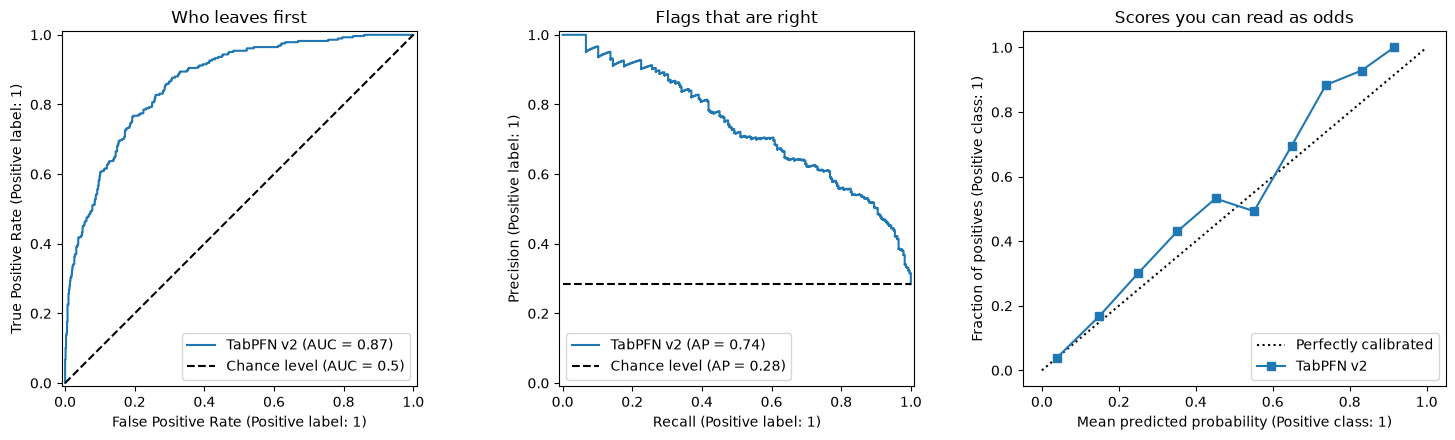

In [8]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

left = upcoming["Churn"] == "Yes"
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
RocCurveDisplay.from_predictions(left, preds["proba_Yes"], name=churn.champion_display, ax=axes[0], plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(left, preds["proba_Yes"], name=churn.champion_display, ax=axes[1], plot_chance_level=True)
CalibrationDisplay.from_predictions(left, preds["proba_Yes"], n_bins=10, name=churn.champion_display, ax=axes[2])
axes[0].set_title("Who leaves first")
axes[1].set_title("Flags that are right")
axes[2].set_title("Scores you can read as odds")
plt.tight_layout()

Text(0.5, 1.0, 'The podium')

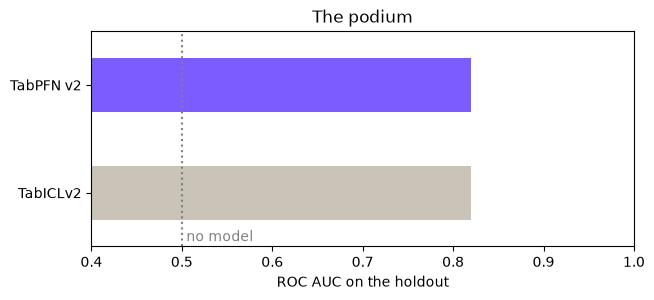

In [9]:
board = churn.evaluation["roc_auc"].sort_values()
ax = board.plot.barh(color=["#c9c3b8" if m != churn.champion_display else "#7c5cff" for m in board.index], figsize=(7, 2 + 0.4 * len(board)))
ax.axvline(0.5, color="gray", ls=":")
ax.text(0.505, -0.45, "no model", color="gray")
ax.set_xlim(0.4, 1)
ax.set_ylabel("")
ax.set_xlabel("ROC AUC on the holdout")
ax.set_title("The podium")

### How much history does the champion need?

A foundation model reads its whole context on every prediction, so a smaller context answers faster. `context_curve` refits the champion on growing samples of its own context and scores each on the rows you pass; the recommended size is the smallest one within 0.005 of the best score that also predicted measurably faster (timings come from one run and are noisy, so a smaller context that wasn't faster is not recommended). If it is smaller than what you have, `update(context_rows=...)` keeps that sample for predictions.

◆ Context curve · TabPFN v2 · 5 sizes · 1,000 test rows


… 100 rows of context


✓ 100 rows · ROC AUC 0.806 · 21.2s


… 200 rows of context


✓ 200 rows · ROC AUC 0.838 · 18.5s


… 400 rows of context


... (3 outputs left out)

… 1,600 rows of context


✓ 1,600 rows · ROC AUC 0.859 · 84.0s


  → 1,600 rows of context score best (ROC AUC 0.859).


,roc_auc,fit_seconds,predict_seconds,ms_per_row,recommended
rows,,,,,
100,0.806,0.06,21.14,21.14,False
200,0.838,0.11,18.41,18.41,False
400,0.837,0.12,26.48,26.48,False
800,0.850,0.13,42.98,42.98,False
1600,0.859,0.18,83.84,83.84,True


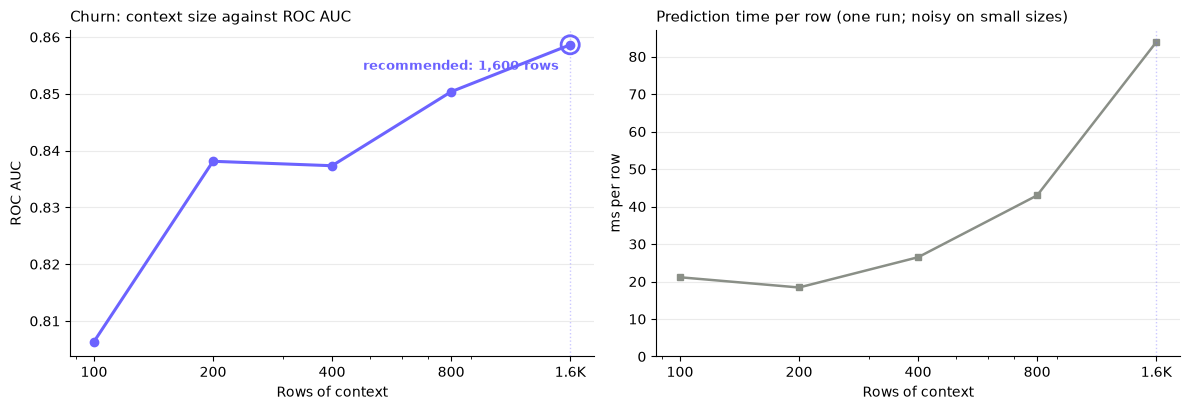

In [10]:
curve = churn.context_curve(upcoming.drop(columns="customerID"), sizes=[100, 200, 400, 800, 1_600])
curve.plot(title="Churn: context size against ROC AUC")
curve

In [11]:
print("recommended context:", curve.recommended, "rows")
churn.update(context_rows=curve.recommended)

recommended context: 1600 rows


<LocalCapability telco-churn · binary · champion TabPFN v2>

In [12]:
churn.save("telco-churn.zg")          # one small file, no weights inside
churn = zerograd.load("telco-churn.zg")
churn

<LocalCapability telco-churn · binary · champion TabPFN v2>

More on the championship, one-row predictions and how much history you need: [quickstart](https://colab.research.google.com/github/zerogradlabs/zerograd-python/blob/main/examples/quickstart.ipynb) and [Titanic](https://colab.research.google.com/github/zerogradlabs/zerograd-python/blob/main/examples/titanic.ipynb).

## 2. House prices: regression

A numeric target with many distinct values is a regression, and the championship switches to RMSE, MAE and R². California housing ships with scikit-learn (it downloads once); the target is the median house value of a block, in units of $100,000.

In [13]:
from sklearn.datasets import fetch_california_housing

houses = fetch_california_housing(as_frame=True).frame.sample(3_000, random_state=0)
train_h, test_h = houses.iloc[:2_000], houses.iloc[2_000:]

prices = zg.create("house-prices", examples=train_h, target="MedHouseVal")
prices.evaluation

✓ 2,000 labeled rows · 8 columns used · regression · MedHouseVal from 0.225 to 5.000


◆ Championship · 2 models · Ranking models, not hyperparameters.


✓ Context 1,600 rows · holdout 400 rows (every row scored)


… TabPFN v2 (1 of 2)


✓ TabPFN v2 (1 of 2) 39.4s


… TabICLv2 (2 of 2)


... (3 outputs left out)

     without a model  1.202  (RMSE, always the average)


◆ Champion: TabICLv2 · RMSE 0.469


  Trained: never. Right: often.


,rmse,mae,r2,seconds,champion
model,,,,,
TabPFN v2,0.520169,0.348026,0.812632,39.35,False
TabICLv2,0.468678,0.300807,0.847891,16.27,True


In [14]:
prices.baselines   # always the average and the median

,rmse,mae,r2
baseline,,,
Always the average,1.201794,0.946186,-0.000152
Always the median,1.244857,0.911991,-0.073112


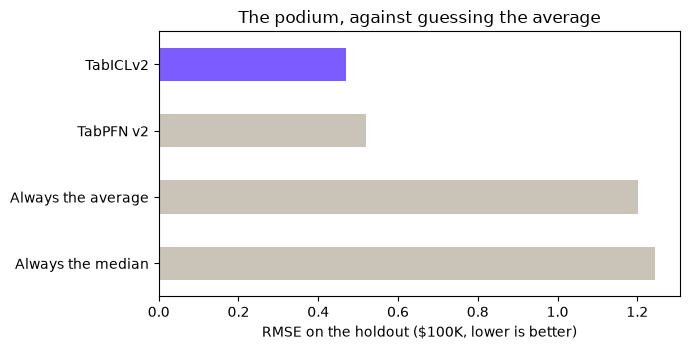

In [15]:
board = pd.concat([prices.evaluation["rmse"], prices.baselines["rmse"]]).sort_values(ascending=False)
colors = ["#7c5cff" if m == prices.champion_display else "#c9c3b8" for m in board.index]
ax = board.plot.barh(color=colors, figsize=(7, 2 + 0.4 * len(board)))
ax.set_ylabel("")
ax.set_xlabel("RMSE on the holdout ($100K, lower is better)")
ax.set_title("The podium, against guessing the average")
plt.tight_layout()

In [16]:
from sklearn.metrics import mean_absolute_error

guess = prices.predict(test_h.drop(columns="MedHouseVal"))
print("MAE on new blocks: $", round(100_000 * mean_absolute_error(test_h["MedHouseVal"], guess["prediction"])))
prices.predict(test_h.drop(columns="MedHouseVal").iloc[0].to_dict())   # a dict in, a dict out

… Warming up TabICLv2 with 2,000 rows of context · In-context learning, in your context.


✓ TabICLv2 ready 18.8s


… Scoring 1,000 rows with TabICLv2 · Answers, no epochs.


✓ Scored 1,000 rows 6.6s


MAE on new blocks: $ 30741


{'prediction': 2.7099342346191406}

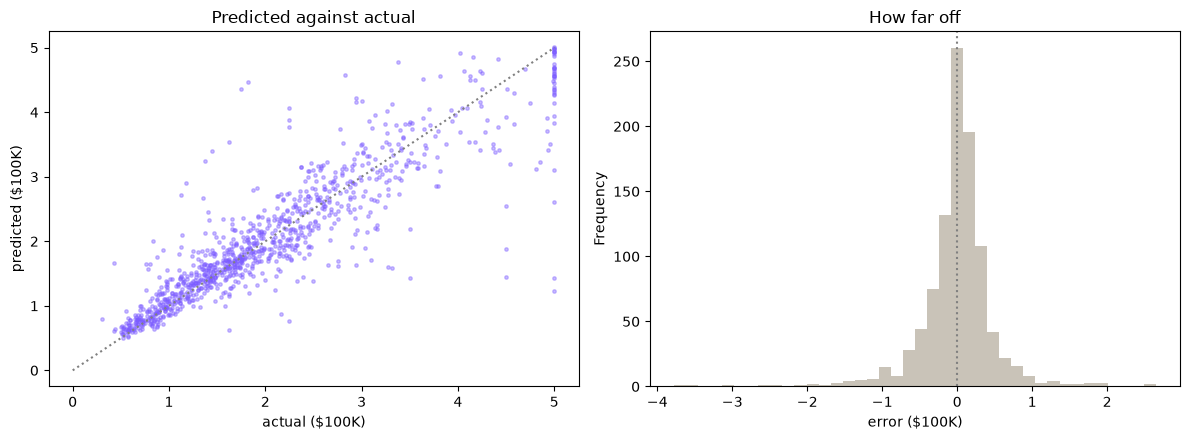

In [17]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))
a.scatter(test_h["MedHouseVal"], guess["prediction"], s=6, alpha=0.4, color="#7c5cff")
lim = [0, max(test_h["MedHouseVal"].max(), guess["prediction"].max())]
a.plot(lim, lim, color="gray", ls=":")
a.set_xlabel("actual ($100K)")
a.set_ylabel("predicted ($100K)")
a.set_title("Predicted against actual")
(guess["prediction"] - test_h["MedHouseVal"].to_numpy()).plot.hist(bins=40, ax=b, color="#c9c3b8")
b.axvline(0, color="gray", ls=":")
b.set_xlabel("error ($100K)")
b.set_title("How far off")
plt.tight_layout()

## 3. Before you ship it

A single holdout is one draw. Before the churn model drives a retention campaign you want to know that it holds on other splits, where to cut the score, and what it is reading.

**Cross-validation.** Every model on 3 folds, next to a baseline, with KS and lift in the top 10% for binary targets. `groups=` and `time=` split by customer or by date when rows repeat or the model will predict the future; the [evaluation notebook](https://colab.research.google.com/github/zerogradlabs/zerograd-python/blob/main/examples/evaluation.ipynb) shows both.

In [18]:
cv = zg.cross_validate(history.drop(columns="customerID"), "Churn", folds=3)
cv.summary

◆ Cross-validation · 3 folds stratified · 2 models · 2,000 rows


… Fold 1 of 3


✓ Fold 1 of 3


… Fold 2 of 3


✓ Fold 2 of 3


… Fold 3 of 3


  🥇 tabicl-v2  ████████████████████████ 0.836


  🥈 tabpfn-v2  ████ 0.833


◆ Champion: tabicl-v2 · mean ROC AUC 0.836


,roc_auc,roc_auc_std,ks,lift_at_10,accuracy,balanced_accuracy,log_loss,pr_auc,f1,precision,recall,folds,seconds
model,,,,,,,,,,,,,
tabicl-v2,0.836377,0.016870,0.540131,2.772198,0.795992,0.696816,0.426854,0.648227,0.555085,0.645541,0.488484,3,60.76
tabpfn-v2,0.832969,0.019294,0.533157,2.753075,0.794991,0.691816,0.430146,0.646099,0.547170,0.646604,0.475096,3,157.87
baseline:majority,0.500000,0.000000,0.000000,1.000000,0.738000,0.500000,0.575139,0.262000,0.000000,0.000000,0.000000,3,0.00


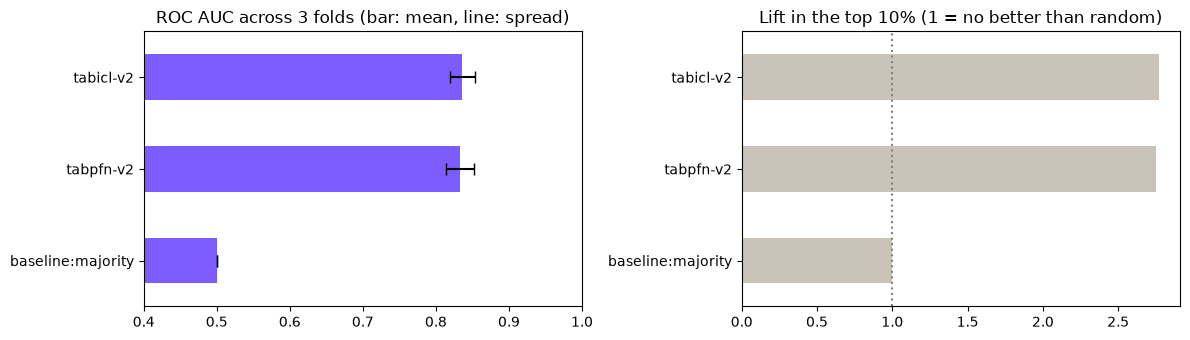

In [19]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5))
summary = cv.summary.sort_values("roc_auc")
summary["roc_auc"].plot.barh(xerr=summary["roc_auc_std"], ax=a, color="#7c5cff", capsize=4)
a.set_xlim(0.4, 1)
a.set_ylabel("")
a.set_title("ROC AUC across 3 folds (bar: mean, line: spread)")
summary["lift_at_10"].plot.barh(ax=b, color="#c9c3b8")
b.axvline(1, color="gray", ls=":")
b.set_ylabel("")
b.set_title("Lift in the top 10% (1 = no better than random)")
plt.tight_layout()

**The threshold.** Say a churner you miss costs 5 times what a retention offer to a loyal customer costs. `optimize_threshold` reads the cut off the championship holdout, with no new predictions, and the capability predicts with it from then on.

In [20]:
cut = churn.optimize_threshold("cost", cost_fp=1, cost_fn=5)
cut

<ThresholdResult · cost · threshold 0.14 · precision 0.435 · recall 0.895 · flags 54.0% of rows · from the championship holdout (400 rows)>

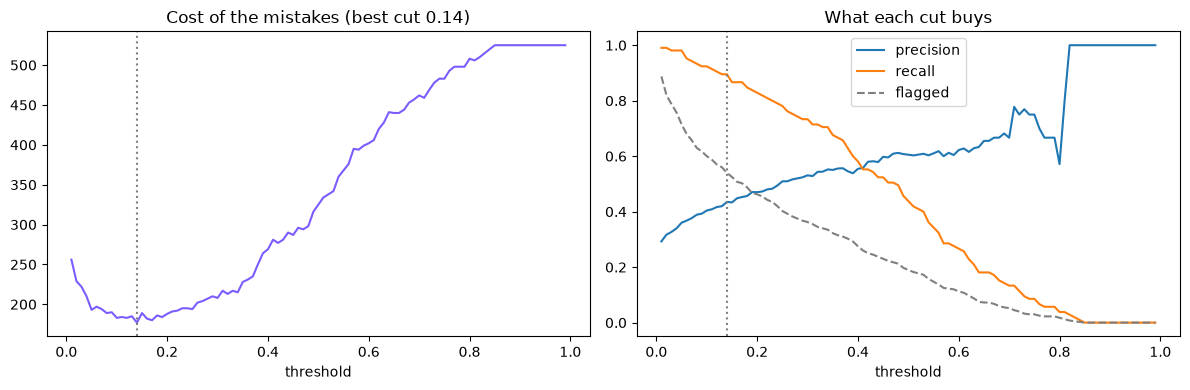

In [21]:
t = cut.table
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
t["cost"].plot(ax=a, color="#7c5cff")
a.axvline(cut.threshold, color="gray", ls=":")
a.set_title(f"Cost of the mistakes (best cut {cut.threshold:.2f})")
a.set_xlabel("threshold")
t[["precision", "recall"]].plot(ax=b)
t["flagged"].plot(ax=b, ls="--", color="gray", label="flagged")
b.axvline(cut.threshold, color="gray", ls=":")
b.set_title("What each cut buys")
b.set_xlabel("threshold")
b.legend()
plt.tight_layout()

In [22]:
from sklearn.metrics import confusion_matrix

flagged = churn.predict(upcoming.drop(columns=["Churn", "customerID"]))
print("threshold", round(churn.threshold, 3))
pd.DataFrame(confusion_matrix(upcoming["Churn"], flagged["prediction"], labels=["No", "Yes"]),
             index=["stayed", "left"], columns=["predicted stays", "predicted leaves"])

… Warming up TabPFN v2 with 1,600 rows of context · In-context learning, in your context.


✓ TabPFN v2 ready 45.7s


… Scoring 1,000 rows with TabPFN v2 · Answers, no epochs.


✓ Scored 1,000 rows 27.2s


threshold 0.14


,predicted stays,predicted leaves
stayed,433,283
left,25,259


The classic scikit-learn classification report, per class, at the threshold the capability now uses. Without arguments it reads the championship holdout; pass rows with the target to score those.

In [23]:
churn.classification_report(upcoming.drop(columns="customerID"))

,precision,recall,f1-score,support
No,0.945415,0.604749,0.737649,716
Yes,0.477860,0.911972,0.627119,284
accuracy,NaN,NaN,0.692000,1000
macro avg,0.711637,0.758360,0.682384,1000
weighted avg,0.812629,0.692000,0.706258,1000


**The columns.** Each column is shuffled in rows the model never read, and the drop in ROC AUC says how much it carried.

… Importance · 19 columns × 2 · 500 rows


✓ Importance of 19 columns 8m51s


,importance,std
column,,
tenure,0.054607,0.004451
InternetService,0.029871,0.000876
Contract,0.029172,0.002810
TotalCharges,0.012226,0.002768
MonthlyCharges,0.012186,0.003269
TechSupport,0.009196,0.010057
OnlineSecurity,0.004898,0.002392
StreamingMovies,0.003138,0.000709
PaperlessBilling,0.003054,0.001036


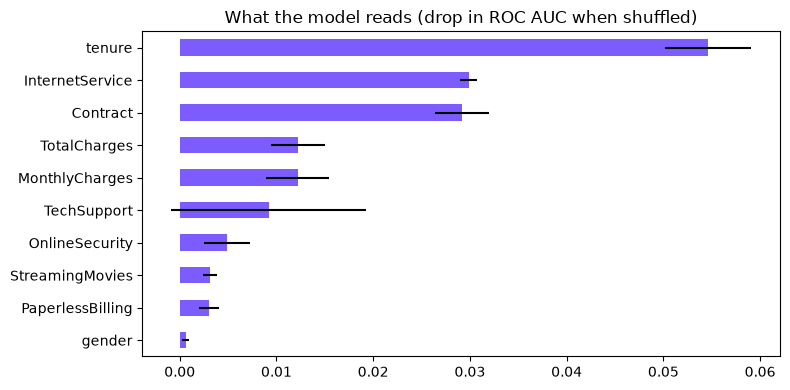

In [24]:
imp = churn.importance(upcoming.drop(columns="customerID"), repeats=2, max_rows=500)
ax = imp.head(10).iloc[::-1].plot.barh(y="importance", xerr="std", legend=False, color="#7c5cff", figsize=(8, 4),
                                        title="What the model reads (drop in ROC AUC when shuffled)")
ax.set_ylabel("")
plt.tight_layout()
imp

Prefer scikit-learn? `ZeroGradClassifier` and `ZeroGradRegressor` drop into pipelines, `cross_val_score` and grid searches:

In [25]:
from sklearn.model_selection import cross_val_score

from zerograd import ZeroGradRegressor

X, y = houses.drop(columns="MedHouseVal").iloc[:1_500], houses["MedHouseVal"].iloc[:1_500]
cross_val_score(ZeroGradRegressor(model="tabicl-v2"), X, y, cv=3, scoring="r2").round(3)

array([0.781, 0.871, 0.877])

## 4. Odd rows: anomaly detection

No target this time. We break 15 customers on purpose (two years of tenure billed like twenty, or a monthly charge no plan has) and ask which rows look wrong. With `labels=` the planted rows score every method, foundation models next to Isolation Forest, LOF and kNN; the label is never read as a feature.

In [26]:
rng = np.random.default_rng(0)
cols = ["tenure", "MonthlyCharges", "TotalCharges", "Contract", "InternetService", "PaymentMethod"]
book = history[cols].dropna().iloc[:800].reset_index(drop=True)
book["broken"] = 0
bad = rng.choice(len(book), 15, replace=False)
book.loc[bad[:8], "TotalCharges"] *= 10
book.loc[bad[8:], "MonthlyCharges"] = rng.uniform(400, 600, 7).round(2)
book.loc[bad, "broken"] = 1

odd = zg.anomalies(book, labels="broken")
odd.evaluation

✓ 800 rows · 6 columns used


… TabPFN v2 · scoring 800 rows


✓ TabPFN v2 scored 3m37s


… TabICLv2 · scoring 800 rows


✓ TabICLv2 scored 3m30s


… FoMo-0D · scoring 800 rows


... (13 outputs left out)

     without a model       0.500  (ROC AUC, random order)


◆ Champion: tabicl-v2 · ROC AUC 0.953 · Built with PriorLabs-TabPFN


◆ 40 unusual rows flagged by tabicl-v2 · top 5% · .top() shows them with why


,roc_auc,pr_auc,kind
model,,,
tabicl-v2,0.953376,0.507460,foundation model
local-outlier-factor,0.944204,0.810096,classic
knn,0.938684,0.867069,classic
tabpfn-v2,0.932569,0.454561,foundation model
fomo-0d,0.929766,0.639285,foundation model
isolation-forest,0.737325,0.053537,classic


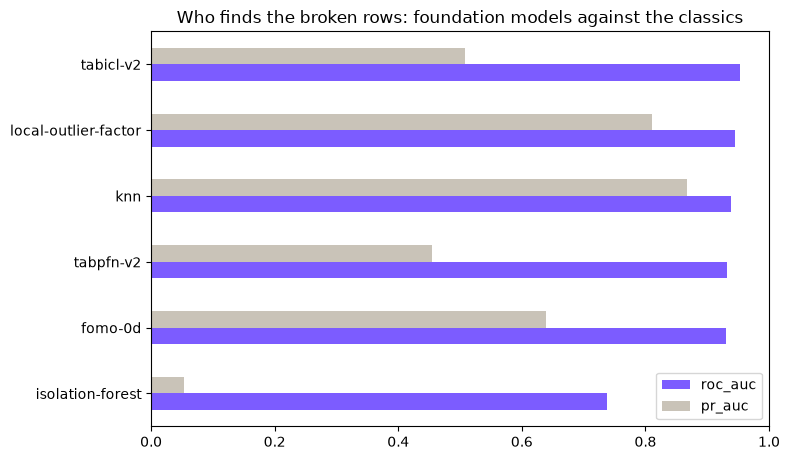

In [27]:
ax = odd.evaluation[["roc_auc", "pr_auc"]].sort_values("roc_auc").plot.barh(figsize=(8, 2 + 0.45 * len(odd.evaluation)),
                                                                           color=["#7c5cff", "#c9c3b8"])
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.set_title("Who finds the broken rows: foundation models against the classics")
plt.tight_layout()

Without labels, the default model scores every row, and TabPFN v2 and TabICLv2 also say which columns make it unusual, in `why`:

In [28]:
blind = zg.anomalies(book.drop(columns="broken"), models=["tabpfn-v2"])
print("planted rows flagged:", int(blind.scores.loc[bad, "is_anomaly"].sum()), "of", len(bad))
blind.top(10)

✓ 800 rows · 6 columns used


… TabPFN v2 · scoring 800 rows


✓ TabPFN v2 scored 3m37s


◆ 40 unusual rows flagged by tabpfn-v2 · top 5% · .top() shows them with why


planted rows flagged: 7 of 15


,anomaly_score,why,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod
501,19.801109,"tenure, MonthlyCharges, InternetService",3,41.35,1072.50,Month-to-month,DSL,Mailed check
484,18.839530,"tenure, InternetService, TotalCharges",19,44.85,8935.50,One year,DSL,Credit card (automatic)
646,18.318181,"tenure, MonthlyCharges, TotalCharges",2,74.75,1448.00,Month-to-month,Fiber optic,Electronic check
776,17.965258,"MonthlyCharges, Contract, tenure",35,508.29,741.00,One year,No,Mailed check
640,14.534170,"MonthlyCharges, InternetService, Contract",9,24.10,259.80,One year,DSL,Bank transfer (automatic)
32,13.976542,"tenure, MonthlyCharges, TotalCharges",26,78.95,20342.50,One year,Fiber optic,Bank transfer (automatic)
758,13.619966,"InternetService, Contract, MonthlyCharges",6,80.25,493.40,Two year,DSL,Mailed check
131,13.332068,"tenure, TotalCharges, MonthlyCharges",13,88.95,1161.75,Two year,DSL,Credit card (automatic)
667,13.158027,"MonthlyCharges, tenure, InternetService",20,24.45,482.80,Month-to-month,DSL,Electronic check
129,12.855003,"InternetService, TotalCharges, tenure",71,76.05,5436.45,Two year,Fiber optic,Electronic check


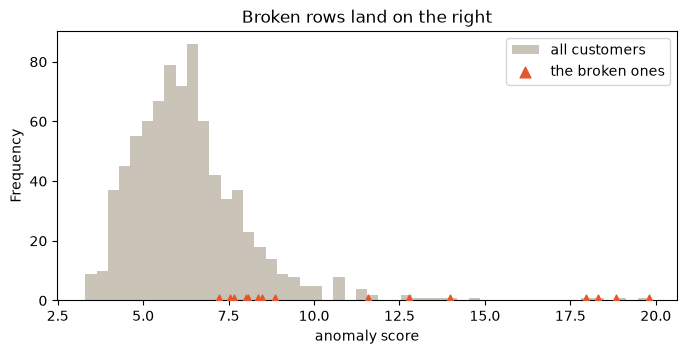

In [29]:
scores = blind.scores["anomaly_score"]
ax = scores.plot.hist(bins=50, color="#c9c3b8", figsize=(8, 3.5), label="all customers")
ax.scatter(scores.loc[bad], np.zeros(len(bad)), color="#e4572e", zorder=3, marker="^", s=60, label="the broken ones")
ax.set_xlabel("anomaly score")
ax.set_title("Broken rows land on the right")
ax.legend()

## 5. Segments: clustering

The wine dataset in scikit-learn: 178 wines, 13 chemical measurements, three cultivars. ZEUS, a zero-shot clustering model, competes with k-means and a Gaussian mixture; the cultivar is used only to score them (adjusted Rand index). Leave `labels` out and the SDK picks `k` for you.

In [30]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True).frame
segments = zg.cluster(wine, labels="target")
segments.evaluation

… ZEUS · grouping 178 rows


✓ ZEUS done 0.9s


… kmeans · grouping 178 rows


✓ kmeans done 0.2s


… gaussian-mixture · grouping 178 rows


✓ gaussian-mixture done 0.1s


... (2 outputs left out)

  🥉 zeus              ████ 0.866


◆ Champion: kmeans · adjusted Rand index 0.897


◆ 3 segments by kmeans · .profiles says what sets each apart


,k,kind,silhouette,adjusted_rand
model,,,,
kmeans,3,classic,0.284859,0.897495
gaussian-mixture,3,classic,0.284859,0.897495
zeus,5,foundation model,0.241091,0.865713


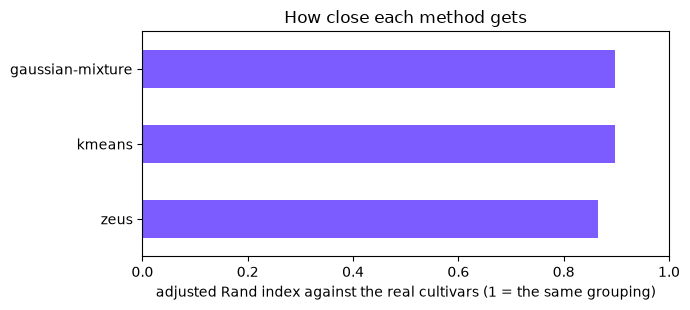

In [31]:
ax = segments.evaluation["adjusted_rand"].sort_values().plot.barh(color="#7c5cff", figsize=(7, 2 + 0.4 * len(segments.evaluation)))
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.set_xlabel("adjusted Rand index against the real cultivars (1 = the same grouping)")
ax.set_title("How close each method gets")
plt.tight_layout()

In [32]:
segments.profiles   # what sets each segment apart

,rows,share,what sets it apart
segment,,,
0,65,0.365,alcohol lower (-0.9 sd); color_intensity lower...
1,51,0.287,od280/od315_of_diluted_wines lower (-1.3 sd); ...
2,62,0.348,proline higher (+1.1 sd); flavanoids higher (+...


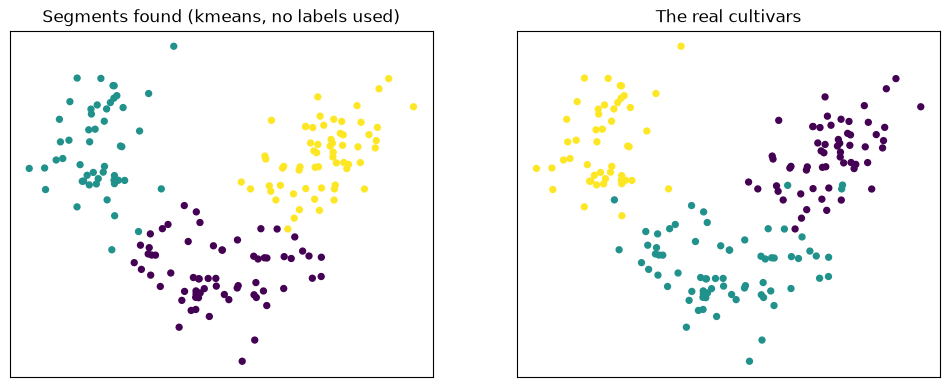

In [33]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

xy = PCA(2).fit_transform(StandardScaler().fit_transform(wine.drop(columns="target")))
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
a.scatter(*xy.T, c=segments.labels, cmap="viridis", s=18)
a.set_title(f"Segments found ({segments.model}, no labels used)")
b.scatter(*xy.T, c=wine["target"], cmap="viridis", s=18)
b.set_title("The real cultivars")
for ax in (a, b):
    ax.set_xticks([])
    ax.set_yticks([])

Imputation and synthetic rows are in the [without a target notebook](https://colab.research.google.com/github/zerogradlabs/zerograd-python/blob/main/examples/no-target.ipynb).

## 6. Production feedback on the platform (optional)

This step needs a ZeroGrad API key. In Colab, add it as a secret named `ZEROGRAD_API_KEY` (the key icon on the left) and give this notebook access; anywhere else, set the environment variable. Without a key the cells below skip themselves.

On the platform every prediction gets a `prediction_id`, and with `id_column` your own id is kept as its reference. When the real outcomes arrive you send them back, and `performance` scores each cohort of predictions next to the holdout. Here the "future" outcomes are the ones we held aside, so you can see the loop end to end in a minute. `maturity_days=0` makes every cohort count right away; in real life you would set it to how long an outcome takes to be known (say 30 days for churn).

Before anything is uploaded, the SDK drops columns that look like personal data on your side and warns you about it.

In [34]:
import os

key = os.environ.get("ZEROGRAD_API_KEY")
if not key:
    try:
        from google.colab import userdata
        key = userdata.get("ZEROGRAD_API_KEY")
    except Exception:
        key = None
print("API key found: running step 6" if key else "No API key: step 6 is skipped")

No API key: step 6 is skipped


In [35]:
if key:
    cloud = ZeroGrad(api_key=key, remote=True)
    remote_churn = cloud.create("telco-churn-demo", examples=history.drop(columns="customerID"), target="Churn")
    display(remote_churn.evaluation)

In [36]:
if key:
    live = remote_churn.predict(upcoming.drop(columns="Churn"), id_column="customerID")
    display(live.head())

In [37]:
if key:
    outcomes = pd.DataFrame({"reference": upcoming["customerID"], "outcome": upcoming["Churn"]})
    print(remote_churn.send_outcomes(outcomes))
    remote_churn.update(maturity_days=0)
    perf = remote_churn.performance(cohort="day")
    display(perf)
    print("overall:", perf.attrs["overall"])
    if not perf.empty and "roc_auc" in perf:
        ax = perf["roc_auc"].plot(marker="o", color="#7c5cff", figsize=(8, 3.5), label="production")
        holdout = perf.attrs.get("holdout")
        if isinstance(holdout, (int, float)):
            ax.axhline(holdout, color="gray", ls=":", label="holdout")
        ax.set_title("ROC AUC by day of prediction")
        ax.legend()

In [38]:
if key:
    remote_churn.delete()   # clean up the demo capability; leave this out to keep it in your workspace

## Where to go next

* Pick the competitors: `ZeroGrad(models=["tabpfn-v2", "mitra-v2"])` (Mitra-v2 and TabDPT come with `pip install "zerograd[all]"`).
* Licenses: TabPFN v2 asks products built with it to show *Built with PriorLabs-TabPFN*. See [MODELS.md](https://github.com/zerogradlabs/zerograd-python/blob/main/MODELS.md) and [TERMS.md](https://github.com/zerogradlabs/zerograd-python/blob/main/TERMS.md).
* Docs: [zerograd.dev/docs](https://zerograd.dev/docs).